In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import load_dataset
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from xgboost.sklearn import XGBRegressor
from sklearn.metrics import mean_squared_error
from catboost import CatBoostRegressor

In [8]:
DATA_DIR = Path("scrabble-player-rating")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
games = pd.read_csv(DATA_DIR / "games.csv")
turns = pd.read_csv(DATA_DIR / "turns.csv")
submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
#print("Working directory:", Path.cwd())
#print("Data directory exists:", DATA_DIR.exists())

In [9]:
datasets = {
    "train": train,
    "test": test,
    "games": games,
    "turns": turns,
    "submission": submission
}
for name, df in datasets.items():
    print(f"\n{'=' * 15} {name.upper()} {'=' * 15}")

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)


=============== TRAIN ===============

Missing values:
game_id     0
nickname    0
score       0
rating      0
dtype: int64

Duplicate rows: 0

Data types:
game_id     int64
nickname      str
score       int64
rating      int64
dtype: object

=============== TEST ===============

Missing values:
game_id         0
nickname        0
score           0
rating      22363
dtype: int64

Duplicate rows: 0

Data types:
game_id       int64
nickname        str
score         int64
rating      float64
dtype: object

=============== GAMES ===============

Missing values:
game_id                  0
first                    0
time_control_name        0
game_end_reason          0
winner                   0
created_at               0
lexicon                  0
initial_time_seconds     0
increment_seconds        0
rating_mode              0
max_overtime_minutes     0
game_duration_seconds    0
dtype: int64

Duplicate rows: 0

Data types:
game_id                    int64
first                        str


In [10]:
turn_features = (
    turns.groupby(["game_id", "nickname"])
    .agg(
        num_turns=("points", "count"),
        avg_points=("points", "mean"),
        max_points=("points", "max"),
        total_points=("points", "sum"),
        std_points=("points", "std")
    )
    .reset_index()
)
train_merged = (
    train
    .merge(
        games,
        on="game_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        turn_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

print("Original rows:", len(train))
print("Merged rows:", len(train_merged))
print(train_merged[[
    "nickname",
    "rating",
    "game_duration_seconds",
    "avg_points"
]].head())

Original rows: 100820
Merged rows: 100820
         nickname  rating  game_duration_seconds  avg_points
0       BetterBot    1637             674.844274   25.769231
1           stevy    1500             674.844274   30.642857
2       davidavid    1811             492.268262   31.428571
3       BetterBot    2071             492.268262   24.461538
4  Inandoutworker    1473             350.861141    8.500000


In [11]:

# Player-disjoint AND game-disjoint train/validation split
# Every human nickname and every game belongs to exactly one set.

from sklearn.model_selection import GroupShuffleSplit

bots = {"BetterBot", "HastyBot", "STEEBot"}

# connect games sharing a human player
game_ids = train_merged["game_id"].drop_duplicates().tolist()
parent = {game_id: game_id for game_id in game_ids}
size = {game_id: 1 for game_id in game_ids}


def find(game_id):
    while parent[game_id] != game_id:
        parent[game_id] = parent[parent[game_id]]
        game_id = parent[game_id]
    return game_id


def union(game_a, game_b):
    root_a = find(game_a)
    root_b = find(game_b)

    if root_a == root_b:
        return

    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a

    parent[root_b] = root_a
    size[root_a] += size[root_b]


human_rows = train_merged.loc[
    ~train_merged["nickname"].isin(bots),
    ["game_id", "nickname"]
].drop_duplicates()

first_game_for_player = {}

for game_id, nickname in human_rows.itertuples(index=False, name=None):
    if nickname in first_game_for_player:
        union(game_id, first_game_for_player[nickname])
    else:
        first_game_for_player[nickname] = game_id

game_groups = np.array([find(game_id) for game_id in game_ids])

n_components = len(set(game_groups))
print("Independent game/player groups:", n_components)

if n_components < 2:
    raise ValueError(
        "Cannot create a player- and game-disjoint split: "
        "all games form one connected component."
    )

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(game_ids, groups=game_groups)
)

train_game_ids = set(np.array(game_ids)[train_idx])
val_game_ids = set(np.array(game_ids)[val_idx])

train_eda = train_merged.loc[
    train_merged["game_id"].isin(train_game_ids)
].copy()

assert train_game_ids.isdisjoint(val_game_ids)

train_players = set(
    human_rows.loc[
        human_rows["game_id"].isin(train_game_ids),
        "nickname"
    ]
)

val_players = set(
    human_rows.loc[
        human_rows["game_id"].isin(val_game_ids),
        "nickname"
    ]
)

assert train_players.isdisjoint(val_players), (
    "Player overlap detected!"
)

print("\nSplit verification")
print("-" * 45)
print("Training games:", len(train_game_ids))
print("Validation games:", len(val_game_ids))
print("Training players:", len(train_players))
print("Validation players:", len(val_players))
print("Overlapping games:",
      len(train_game_ids & val_game_ids))
print("Overlapping human players:",
      len(train_players & val_players))
print("Validation game fraction:",
      round(len(val_game_ids) / len(game_ids), 3))


Independent game/player groups: 1028

Split verification
---------------------------------------------
Training games: 42213
Validation games: 8197
Training players: 822
Validation players: 206
Overlapping games: 0
Overlapping human players: 0
Validation game fraction: 0.163


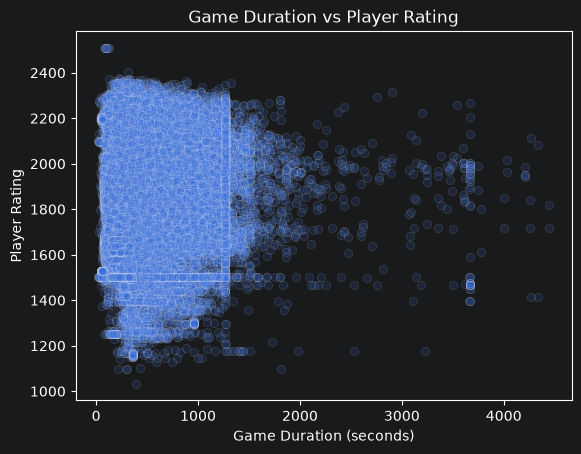

time_control_name
regular       72008
blitz          6306
rapid          5820
ultrablitz      292
Name: count, dtype: int64


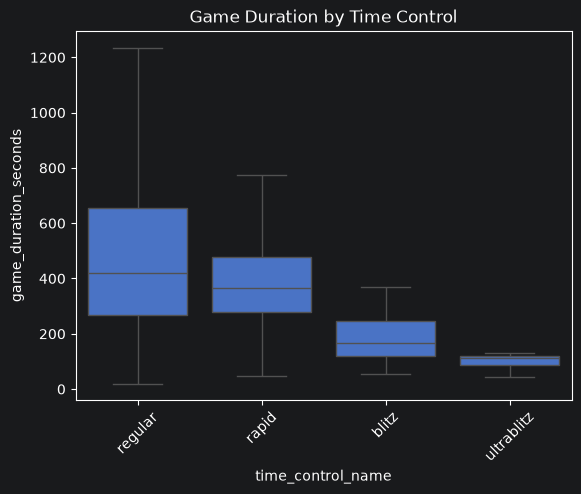

In [12]:
eda_df = train_eda.dropna(
    subset=["rating", "game_duration_seconds"]
).copy()

sns.scatterplot(
    data=eda_df,
    x="game_duration_seconds",
    y="rating",
    alpha=0.15
)

plt.title("Game Duration vs Player Rating")
plt.xlabel("Game Duration (seconds)")
plt.ylabel("Player Rating")
plt.show()

print(eda_df["time_control_name"].value_counts())

sns.boxplot(
    data=eda_df,
    x="time_control_name",
    y="game_duration_seconds",
    showfliers=False
)

plt.xticks(rotation=45)
plt.title("Game Duration by Time Control")
plt.show()

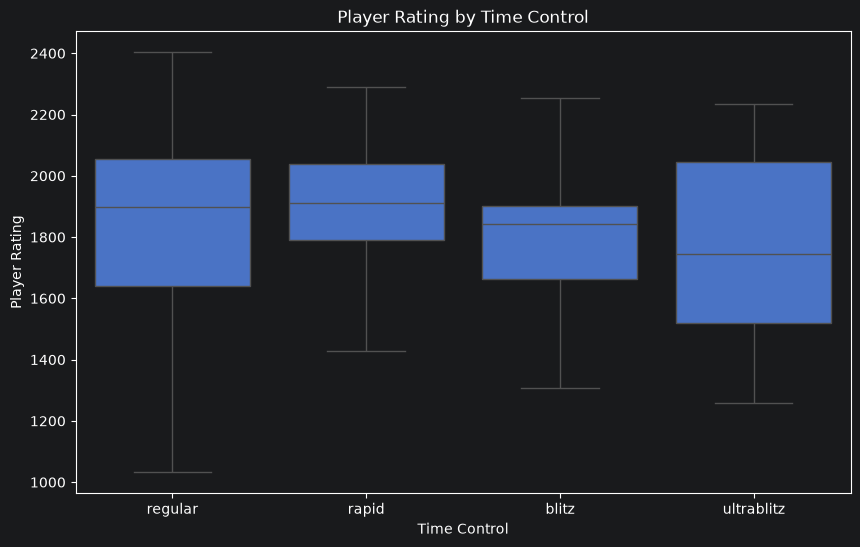

,count,mean,median,std
time_control_name,,,,
blitz,6306,1812.90,1842.0,176.64
rapid,5820,1902.60,1912.0,197.76
regular,72008,1860.33,1897.0,239.59
ultrablitz,292,1779.70,1744.5,261.36


In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda_df,
    x="time_control_name",
    y="rating",
    showfliers=False
)

plt.title("Player Rating by Time Control")
plt.xlabel("Time Control")
plt.ylabel("Player Rating")
plt.show()
rating_by_time = (
    eda_df.groupby("time_control_name")["rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(rating_by_time)

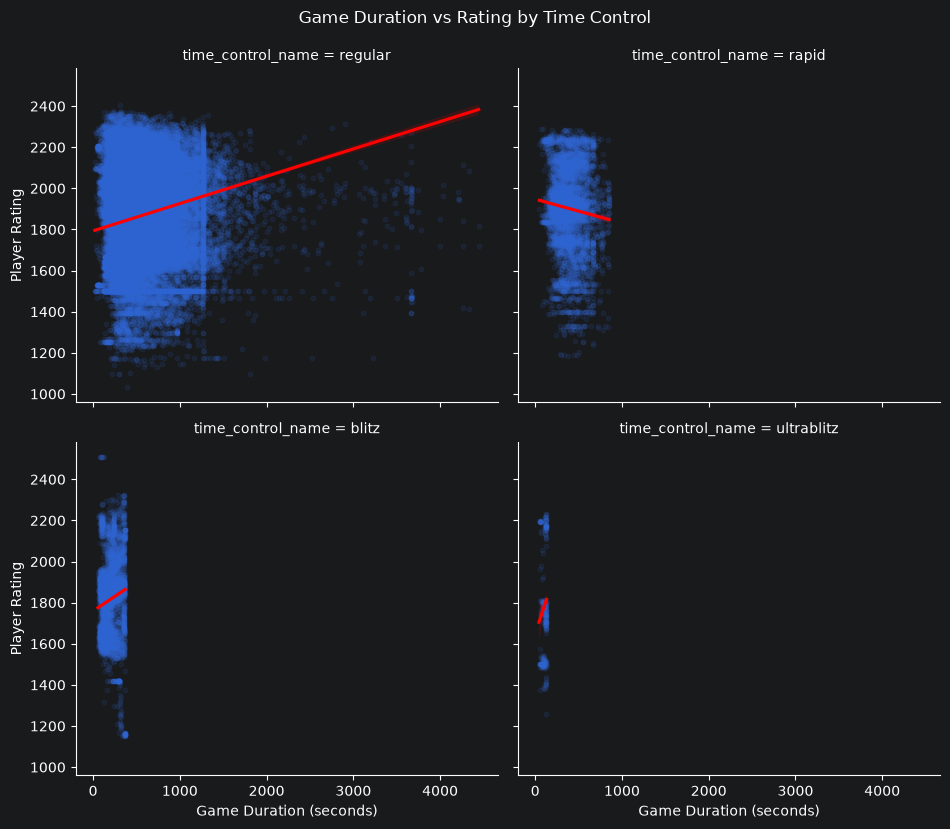

time_control_name
blitz         0.131493
rapid        -0.085809
regular       0.183568
ultrablitz    0.109696
dtype: float64


In [14]:
g = sns.lmplot(
    data=eda_df,
    x="game_duration_seconds",
    y="rating",
    col="time_control_name",
    col_wrap=2,
    scatter_kws={"alpha": 0.1, "s": 10},
    line_kws={"color": "red"},
    height=4,
    aspect=1.2
)

g.set_axis_labels("Game Duration (seconds)", "Player Rating")
g.fig.suptitle("Game Duration vs Rating by Time Control", y=1.03)

plt.show()
correlations = (
    eda_df.groupby("time_control_name")
    .apply(
        lambda group: group["game_duration_seconds"]
        .corr(group["rating"]),
        include_groups=False
    )
)

print(correlations)

In [15]:
results = []

for mode, group in eda_df.groupby("time_control_name"):
    results.append({
        "time_control": mode,
        "n_games": len(group),
        "pearson": group["game_duration_seconds"].corr(
            group["rating"], method="pearson"
        ),
        "spearman": group["game_duration_seconds"].corr(
            group["rating"], method="spearman"
        )
    })

correlation_results = pd.DataFrame(results)

display(correlation_results.round(3))

,time_control,n_games,pearson,spearman
0,blitz,6306,0.131,0.173
1,rapid,5820,-0.086,-0.062
2,regular,72008,0.184,0.283
3,ultrablitz,292,0.110,0.123


avg_points               0.453582
score                    0.406698
total_points             0.406698
game_duration_seconds    0.274687
max_points               0.213362
std_points               0.180225
num_turns               -0.247474
Name: rating, dtype: float64

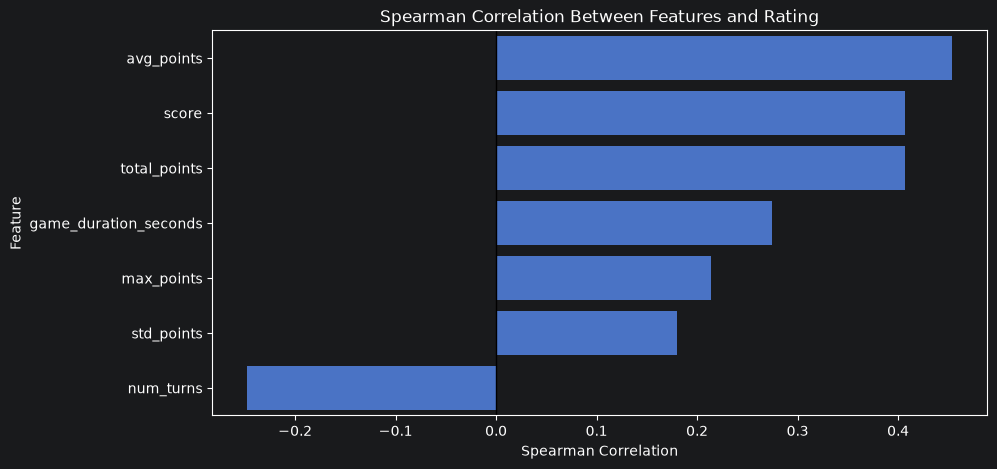

In [16]:
numeric_features = [
    "score",
    "num_turns",
    "avg_points",
    "max_points",
    "total_points",
    "std_points",
    "game_duration_seconds"
]

correlations = (
    train_eda[numeric_features + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation Between Features and Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")

plt.axvline(0, color="black", linewidth=1)
plt.show()

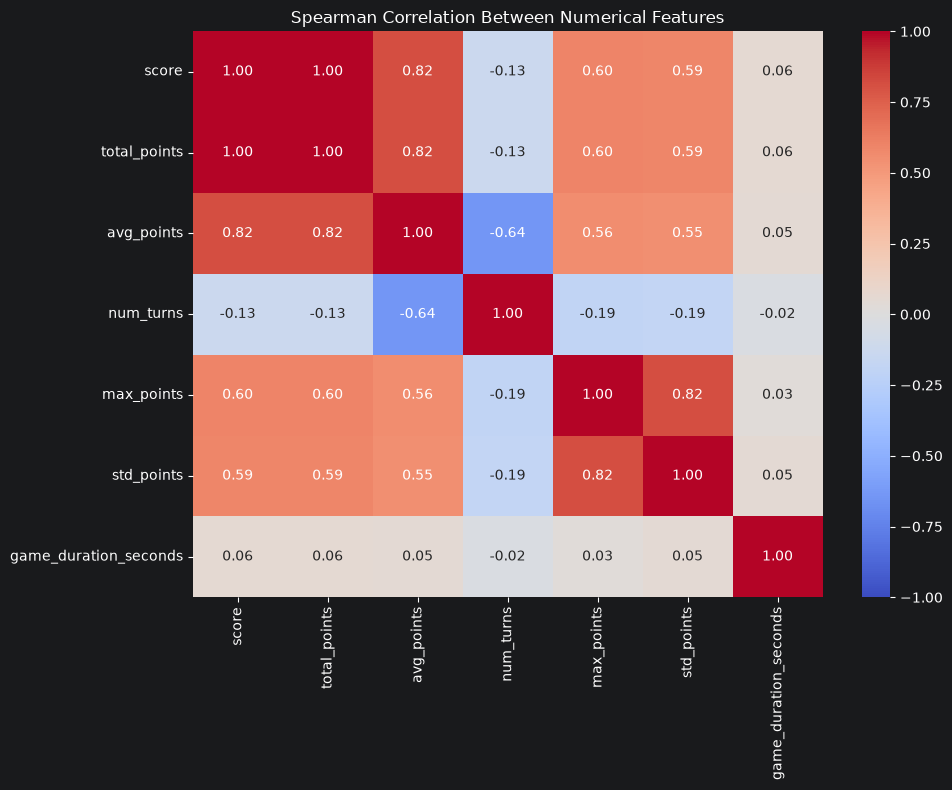

In [17]:
features = [
    "score",
    "total_points",
    "avg_points",
    "num_turns",
    "max_points",
    "std_points",
    "game_duration_seconds"
]

corr_matrix = train_eda[features].corr(method="spearman")

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [18]:
feature_summary = pd.DataFrame({
    "dtype": train_eda.dtypes.astype(str),
    "unique_values": train_eda.nunique(),
    "example": train_eda.iloc[0]
})

display(feature_summary.sort_values("unique_values"))

,dtype,unique_values,example
rating_mode,str,2,CASUAL
winner,int64,3,1
game_end_reason,str,4,STANDARD
time_control_name,str,4,regular
lexicon,str,4,NWL20
max_overtime_minutes,int64,8,1
increment_seconds,int64,8,0
num_turns,int64,29,13
initial_time_seconds,int64,34,1200
max_points,int64,168,68


In [19]:
categorical_features = [
    "rating_mode",
    "winner",
    "game_end_reason",
    "time_control_name",
    "lexicon"
]

In [20]:
for col in categorical_features:
    print(f"\n===== {col} =====")

    summary = (
        train_eda.groupby(col, dropna=False)
        .agg(
            games=("rating", "size"),
            mean_rating=("rating", "mean"),
            median_rating=("rating", "median"),
            std_rating=("rating", "std")
        )
        .sort_values("games", ascending=False)
    )

    display(summary.round(2))


===== rating_mode =====


,games,mean_rating,median_rating,std_rating
rating_mode,,,,
RATED,57906,1923.53,1950.0,203.95
CASUAL,26520,1719.44,1640.0,232.85



===== winner =====


,games,mean_rating,median_rating,std_rating
winner,,,,
0,53482,1858.76,1883.0,235.98
1,30660,1860.85,1893.0,229.14
-1,284,1828.68,1836.0,236.46



===== game_end_reason =====


,games,mean_rating,median_rating,std_rating
game_end_reason,,,,
STANDARD,79762,1857.79,1884.0,232.36
RESIGNED,2248,1901.23,1954.0,240.50
TIME,2096,1894.69,1937.5,259.20
CONSECUTIVE_ZEROES,320,1741.69,1664.0,222.67



===== time_control_name =====


,games,mean_rating,median_rating,std_rating
time_control_name,,,,
regular,72008,1860.33,1897.0,239.59
blitz,6306,1812.90,1842.0,176.64
rapid,5820,1902.60,1912.0,197.76
ultrablitz,292,1779.70,1744.5,261.36



===== lexicon =====


,games,mean_rating,median_rating,std_rating
lexicon,,,,
CSW21,48974,1986.28,2009.0,189.94
NWL20,22278,1752.71,1746.5,166.06
ECWL,13166,1568.23,1598.0,69.63
NSWL20,8,1625.50,1565.5,230.55


In [21]:
print("\nMost common first values:")
display(train_merged["first"].value_counts().head(15))

print("\nExamples of player pairs:")
display(
    train_merged.loc[
        train_merged["game_id"].isin(train_game_ids),
        ["game_id", "nickname", "first", "rating"]
    ].head(20)
)


Most common first values:


first
HastyBot      17144
BetterBot     16552
STEEBot       16286
BB-8           6576
pandorable     1760
Goldenlamb     1094
kar2008         602
HivinD          578
Rexington       572
Anita           564
talulah         530
deathstar       522
Kovert          516
Matt_86         464
Kathleen3       460
Name: count, dtype: int64


Examples of player pairs:


,game_id,nickname,first,rating
0,1,BetterBot,BetterBot,1637
1,1,stevy,BetterBot,1500
2,3,davidavid,BetterBot,1811
3,3,BetterBot,BetterBot,2071
4,4,Inandoutworker,BetterBot,1473
5,4,BetterBot,BetterBot,1936
6,5,stevy,STEEBot,1500
7,5,STEEBot,STEEBot,1844
12,9,cccc,BetterBot,1641
13,9,BetterBot,BetterBot,1624


In [22]:
train_merged["played_first"] = (
    train_merged["nickname"] == train_merged["first"]
).astype(int)

display(train_merged["nickname"].value_counts().head(20))

train_merged["player_won"] = (
    ((train_merged["played_first"] == 1) &
     (train_merged["winner"] == 0)) |
    ((train_merged["played_first"] == 0) &
     (train_merged["winner"] == 1))
).astype(int)

display(
    train_merged.loc[
        train_merged["game_id"].isin(train_game_ids)
    ]
    .groupby("player_won")["rating"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

nickname
HastyBot      17346
BetterBot     16602
STEEBot       16462
BB-8           6576
pandorable     1759
Goldenlamb     1029
HivinD          592
kar2008         576
Rexington       561
Anita           555
talulah         522
deathstar       511
Kovert          503
Matt_86         461
Kathleen3       451
Trayz           441
stevy           410
tarkovsky7      399
Glilac          388
Esan            384
Name: count, dtype: int64

,count,mean,median,std
player_won,,,,
0,42355,1853.20,1881.0,234.61
1,42071,1865.68,1892.0,232.27


In [23]:
opponent_scores = train_merged[
    ["game_id", "nickname", "score"]
].rename(columns={
    "nickname": "opponent_nickname",
    "score": "opponent_score"
})

score_pairs = train_merged.merge(
    opponent_scores,
    on="game_id",
    how="left",
    validate="many_to_many"
)

# remove the self match, leaving the opponent's row
score_pairs = score_pairs[
    score_pairs["nickname"] != score_pairs["opponent_nickname"]
].copy()

score_pairs["score_difference"] = (
    score_pairs["score"] - score_pairs["opponent_score"]
)

display(
    score_pairs[
        [
            "game_id",
            "nickname",
            "score",
            "opponent_nickname",
            "opponent_score",
            "score_difference"
        ]
    ].head(12)
)

print("Original rows:", len(train_merged))
print("Rows after joining:", len(score_pairs))

,game_id,nickname,score,opponent_nickname,opponent_score,score_difference
1,1,BetterBot,335,stevy,429,-94
2,1,stevy,429,BetterBot,335,94
5,3,davidavid,440,BetterBot,318,122
6,3,BetterBot,318,davidavid,440,-122
9,4,Inandoutworker,119,BetterBot,478,-359
10,4,BetterBot,478,Inandoutworker,119,359
13,5,stevy,325,STEEBot,427,-102
14,5,STEEBot,427,stevy,325,102
17,6,HivinD,378,STEEBot,427,-49
18,6,STEEBot,427,HivinD,378,49


Original rows: 100820
Rows after joining: 100820


score               0.406698
score_difference    0.248626
Name: rating, dtype: float64

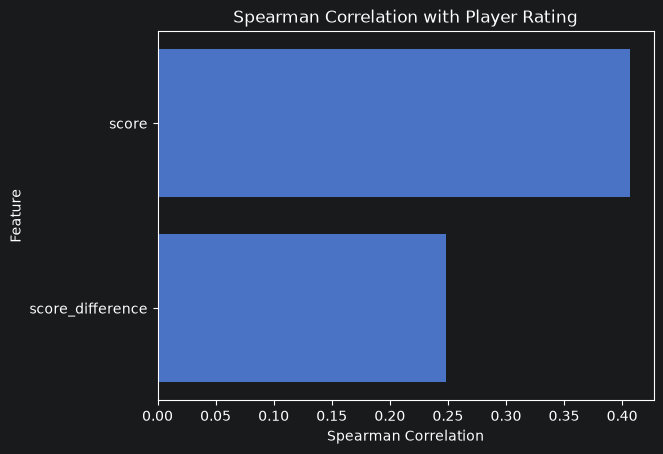

In [24]:
features = ["score", "score_difference"]

correlations = (
    score_pairs.loc[
        score_pairs["game_id"].isin(train_game_ids),
        features + ["rating"]
    ]
    .corr(method="spearman")["rating"]
    .drop("rating")
)

display(correlations)

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation with Player Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black")
plt.show()

In [25]:
selected_features = [
    # numerical features
    "score",
    "avg_points",
    "num_turns",
    "max_points",
    "std_points",
    "game_duration_seconds",
    "initial_time_seconds",
    "increment_seconds",
    "max_overtime_minutes",
    "score_difference",

    # categorical features
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason",

    # binary features
    "played_first",
    "player_won"
]

# target variable
target = "rating"

# final df
train_final = score_pairs[
    selected_features + [target]
].copy()

print("Shape:", train_final.shape)
display(train_final.head())

Shape: (100820, 17)


,score,avg_points,num_turns,max_points,std_points,game_duration_seconds,initial_time_seconds,increment_seconds,max_overtime_minutes,score_difference,rating_mode,lexicon,time_control_name,game_end_reason,played_first,player_won,rating
1,335,25.769231,13,68,16.457794,674.844274,1200,0,1,-94,CASUAL,NWL20,regular,STANDARD,1,0,1637
2,429,30.642857,14,98,25.490895,674.844274,1200,0,1,94,CASUAL,NWL20,regular,STANDARD,0,1,1500
5,440,31.428571,14,103,21.689112,492.268262,900,0,5,122,RATED,CSW21,regular,STANDARD,0,1,1811
6,318,24.461538,13,76,18.058310,492.268262,900,0,5,-122,RATED,CSW21,regular,STANDARD,1,0,2071
9,119,8.500000,14,26,8.600089,350.861141,3600,0,1,-359,CASUAL,CSW21,regular,RESIGNED,0,0,1473


In [26]:



bots = {"BetterBot", "HastyBot", "STEEBot"}

train_rows = score_pairs[
    score_pairs["game_id"].isin(train_game_ids)
]

val_rows = score_pairs[
    score_pairs["game_id"].isin(val_game_ids)
]

train_games = set(train_rows["game_id"])
val_games = set(val_rows["game_id"])

train_players = set(
    train_rows.loc[
        ~train_rows["nickname"].isin(bots),
        "nickname"
    ]
)

val_players = set(
    val_rows.loc[
        ~val_rows["nickname"].isin(bots),
        "nickname"
    ]
)

game_overlap = train_games & val_games
player_overlap = train_players & val_players

print("Training games:", len(train_games))
print("Validation games:", len(val_games))
print("Training human players:", len(train_players))
print("Validation human players:", len(val_players))
print("Overlapping games:", len(game_overlap))
print("Overlapping human players:", len(player_overlap))

assert not game_overlap, "Game leakage detected!"
assert not player_overlap, "Player leakage detected!"

print("\nSUCCESS: Both games and human players are disjoint.")


Training games: 42213
Validation games: 8197
Training human players: 822
Validation human players: 206
Overlapping games: 0
Overlapping human players: 0

SUCCESS: Both games and human players are disjoint.


In [27]:
display(turns["turn_type"].value_counts(dropna=False))
move_type_counts = pd.crosstab(
    index=[turns["game_id"], turns["nickname"]],
    columns=turns["turn_type"].fillna("Unknown")
).add_prefix("count_").reset_index()

display(move_type_counts.head())

turn_type
Play             1872864
End                67987
Exchange           48997
Pass                8065
Timeout             4143
Challenge           2571
Six-Zero Rule        476
NaN                  395
Name: count, dtype: int64

turn_type,game_id,nickname,count_Challenge,count_End,count_Exchange,count_Pass,count_Play,count_Six-Zero Rule,count_Timeout,count_Unknown
0,1,BetterBot,0,0,0,0,13,0,0,0
1,1,stevy,0,1,0,0,13,0,0,0
2,2,BetterBot,0,0,0,0,12,0,0,0
3,2,Super,0,1,1,1,11,0,0,0
4,3,BetterBot,0,0,1,0,12,0,0,0


count_End              0.078740
count_Challenge        0.047860
count_Unknown         -0.018460
count_Six-Zero Rule   -0.030640
count_Pass            -0.040318
count_Timeout         -0.056459
count_Exchange        -0.145628
count_Play            -0.255551
Name: rating, dtype: float64

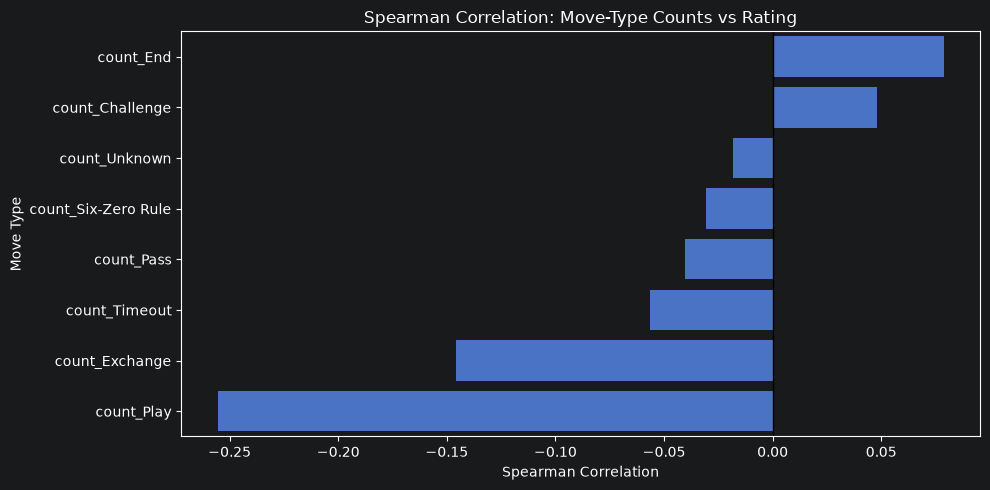

In [28]:

move_type_counts = pd.crosstab(
    index=[turns["game_id"], turns["nickname"]],
    columns=turns["turn_type"].fillna("Unknown")
).add_prefix("count_").reset_index()

moves_merged = score_pairs.merge(
    move_type_counts,
    on=["game_id", "nickname"],
    how="left",
    validate="one_to_one"
)

move_cols = [
    col for col in move_type_counts.columns
    if col.startswith("count_")
]

train_moves = moves_merged.loc[
    moves_merged["game_id"].isin(train_game_ids)
].copy()

correlations = (
    train_moves[move_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.title("Spearman Correlation: Move-Type Counts vs Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Move Type")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


rate_End              0.142440
rate_Challenge        0.047874
rate_Play             0.006788
rate_Unknown         -0.018440
rate_Six-Zero Rule   -0.030664
rate_Pass            -0.040217
rate_Timeout         -0.056154
rate_Exchange        -0.138312
Name: rating, dtype: float64

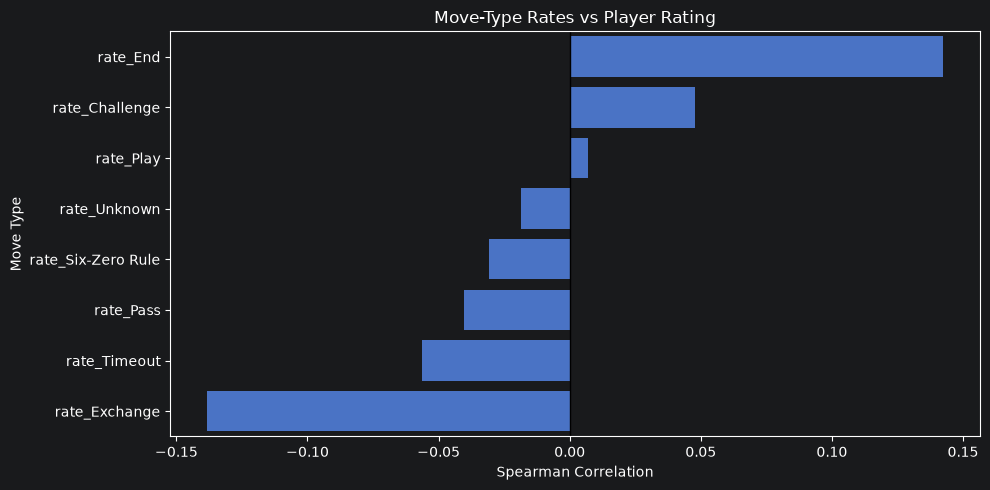

In [29]:

move_rate_cols = []


for col in move_cols:
    rate_col = col.replace("count_", "rate_")

    moves_merged[rate_col] = (
        moves_merged[col] /
        moves_merged["num_turns"].replace(0, np.nan)
    )

    move_rate_cols.append(rate_col)

train_moves = moves_merged.loc[
    moves_merged["game_id"].isin(train_game_ids)
].copy()

rate_correlations = (
    train_moves[move_rate_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(rate_correlations)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rate_correlations.values,
    y=rate_correlations.index
)

plt.title("Move-Type Rates vs Player Rating")
plt.xlabel("Spearman Correlation")
plt.ylabel("Move Type")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()


In [30]:
display(
    moves_merged["count_End"]
    .value_counts()
    .sort_index()
)

display(
    moves_merged.groupby("count_End")["num_turns"]
    .agg(["count", "mean", "median"])
)
display(
    pd.crosstab(
        moves_merged["count_End"],
        moves_merged["player_won"],
        normalize="index"
    ).round(3)
)

count_End
0    53126
1    47694
Name: count, dtype: int64

,count,mean,median
count_End,,,
0,53126,13.106087,13.0
1,47694,14.572378,14.0


player_won,0,1
count_End,,
0,0.506,0.494
1,0.498,0.502


In [31]:


expanded_data = moves_merged.copy()

print("Expanded data initialized:", expanded_data.shape)

Expanded data initialized: (100820, 41)


Spearman correlations with rating — training only


move_length_mean         0.289106
move_length_max          0.226803
move_length_std          0.218065
rack_vowel_ratio_std     0.017251
rack_vowel_ratio_mean   -0.027623
Name: rating, dtype: float64


Missing values in human training data:


move_length_mean         0
move_length_std          0
move_length_max          0
rack_vowel_ratio_mean    0
rack_vowel_ratio_std     0
dtype: int64

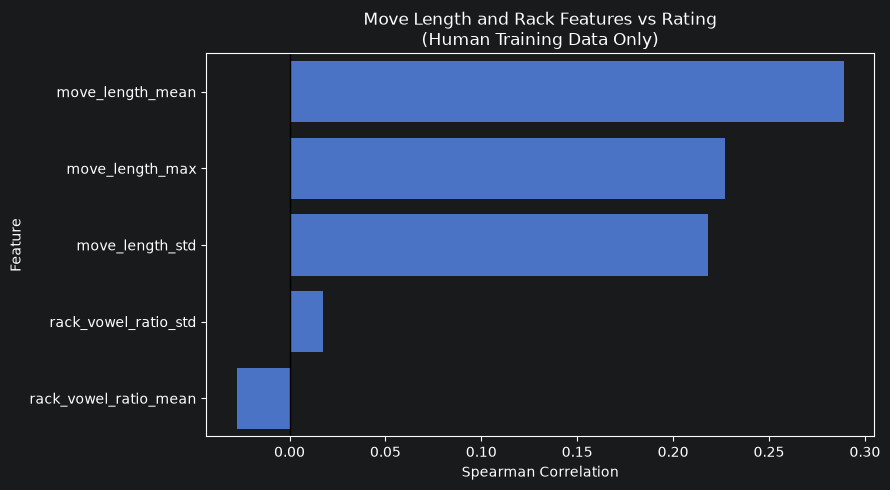

In [32]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



t = turns.copy()

t["move_letters"] = (
    t["move"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_length"] = (
    t["move_letters"]
    .str.len()
    .astype(float)
)

t.loc[t["move"].isna(), "move_length"] = np.nan

t["rack_letters"] = (
    t["rack"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["rack_length"] = (
    t["rack_letters"]
    .str.len()
    .astype(float)
)

t["rack_vowels"] = (
    t["rack_letters"]
    .str.count(r"[AEIOU]")
    .astype(float)
)

t["rack_vowel_ratio"] = (
    t["rack_vowels"] /
    t["rack_length"].replace(0, np.nan)
)


new_turn_features = (
    t.groupby(["game_id", "nickname"])
    .agg(
        move_length_mean=("move_length", "mean"),
        move_length_std=("move_length", "std"),
        move_length_max=("move_length", "max"),
        rack_vowel_ratio_mean=("rack_vowel_ratio", "mean"),
        rack_vowel_ratio_std=("rack_vowel_ratio", "std")
    )
    .reset_index()
)

feature_cols = [
    "move_length_mean",
    "move_length_std",
    "move_length_max",
    "rack_vowel_ratio_mean",
    "rack_vowel_ratio_std"
]

original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=feature_cols, errors="ignore")
    .merge(
        new_turn_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

bots = ["BetterBot", "HastyBot", "STEEBot"]

eda_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()


assert set(eda_train["game_id"]).isdisjoint(val_game_ids)

correlations = (
    eda_train[feature_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Spearman correlations with rating — training only")
display(correlations)

print("\nMissing values in human training data:")
display(
    eda_train[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(9, 5))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title(
    "Move Length and Rack Features vs Rating\n"
    "(Human Training Data Only)"
)
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
selected_move_features = [
    "move_length_mean",
    "move_length_max",
    "move_length_std"
]

In [33]:

# ============================================================
# Historical Player Performance Features
# Only games BEFORE the current game
# No rating leakage / No competition test data
# ============================================================

import numpy as np
import pandas as pd

bots = ["BetterBot", "HastyBot", "STEEBot"]

history_cols = [
    "historical_score_mean",
    "historical_score_std",
    "historical_games_count"
]

# 1. Prepare game timestamps
game_dates = games[["game_id", "created_at"]].copy()

assert not game_dates["game_id"].duplicated().any()

game_dates["created_at"] = pd.to_datetime(
    game_dates["created_at"],
    errors="coerce",
    utc=True
)

# 2. Use existing human observations only
# No rating column is used
player_history = expanded_data.loc[
    ~expanded_data["nickname"].isin(bots),
    ["game_id", "nickname", "score"]
].copy()

assert not player_history.duplicated(
    ["game_id", "nickname"]
).any()

player_history = player_history.merge(
    game_dates,
    on="game_id",
    how="left",
    validate="many_to_one"
)

player_history["score"] = pd.to_numeric(
    player_history["score"],
    errors="coerce"
)

# 3. Aggregate by player and exact timestamp
# Games at the same timestamp cannot be history
# for one another.
valid_history = player_history.dropna(
    subset=["created_at", "score"]
).copy()

valid_history["score_squared"] = (
    valid_history["score"] ** 2
)

time_stats = (
    valid_history
    .groupby(["nickname", "created_at"], as_index=False)
    .agg(
        current_n=("score", "count"),
        current_sum=("score", "sum"),
        current_sum_sq=("score_squared", "sum")
    )
    .sort_values(["nickname", "created_at"])
    .reset_index(drop=True)
)

# 4. Cumulative statistics BEFORE current timestamp
grouped = time_stats.groupby("nickname")

time_stats["prev_n"] = (
    grouped["current_n"].cumsum()
    - time_stats["current_n"]
)

time_stats["prev_sum"] = (
    grouped["current_sum"].cumsum()
    - time_stats["current_sum"]
)

time_stats["prev_sum_sq"] = (
    grouped["current_sum_sq"].cumsum()
    - time_stats["current_sum_sq"]
)

# 5. Historical mean
n = time_stats["prev_n"]
s = time_stats["prev_sum"]
s2 = time_stats["prev_sum_sq"]

time_stats["historical_games_count"] = n

time_stats["historical_score_mean"] = (
    s / n.where(n > 0)
)

# Sample standard deviation (ddof=1)
historical_variance = (
    (s2 - s**2 / n.where(n > 0))
    / (n - 1).where(n > 1)
)

time_stats["historical_score_std"] = np.sqrt(
    historical_variance.clip(lower=0)
)

# 6. Map historical features back to player-games
player_history = player_history.merge(
    time_stats[
        ["nickname", "created_at"] + history_cols
    ],
    on=["nickname", "created_at"],
    how="left",
    validate="many_to_one"
)

# Players without known timestamps have no usable history
player_history["historical_games_count"] = (
    player_history["historical_games_count"].fillna(0)
)

# 7. Merge into expanded_data (safe to rerun)
original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=history_cols, errors="ignore")
    .merge(
        player_history[
            ["game_id", "nickname"] + history_cols
        ],
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

# 8. Training-only summary
history_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()

assert set(history_train["game_id"]).isdisjoint(
    val_game_ids
)

print("Historical features successfully created.")
print("\nTraining missing values:")
print(history_train[history_cols].isna().sum())

print("\nTraining-only Spearman correlations:")
display(
    history_train[history_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("\nExample observations:")
display(
    player_history.sort_values(
        ["nickname", "created_at"]
    )[
        ["nickname", "game_id", "created_at", "score"]
        + history_cols
    ].head(15)
)


Historical features successfully created.

Training missing values:
historical_score_mean      822
historical_score_std      1506
historical_games_count       0
dtype: int64

Training-only Spearman correlations:


historical_score_mean     0.592333
historical_score_std      0.301180
historical_games_count   -0.251937
Name: rating, dtype: float64


Example observations:


,nickname,game_id,created_at,score,historical_score_mean,historical_score_std,historical_games_count
30373,0188889876,43828,2022-09-11 13:06:11+00:00,15,NaN,NaN,0
3987,0927399533,5765,2022-08-09 14:25:28+00:00,141,NaN,NaN,0
27925,0927399533,40264,2022-08-09 15:26:54+00:00,212,141.000000,NaN,1
30764,0927399533,44376,2022-08-10 16:28:43+00:00,227,176.500000,50.204581,2
22630,0927399533,32633,2022-08-10 16:49:00+00:00,391,193.333333,45.938365,3
2979,0927399533,4315,2022-08-10 23:58:18+00:00,149,242.750000,105.711478,4
31300,0927399533,45148,2022-08-11 05:48:29+00:00,290,224.000000,100.692602,5
45390,0927399533,65516,2022-08-15 06:33:56+00:00,313,235.000000,94.006383,6
39331,0927399533,56816,2022-08-15 07:21:06+00:00,226,246.142857,90.738504,7
13616,0927399533,19582,2022-08-15 07:32:13+00:00,316,243.625000,84.308850,8


high_score_rate     0.331598
high_score_count    0.292506
Name: rating, dtype: float64

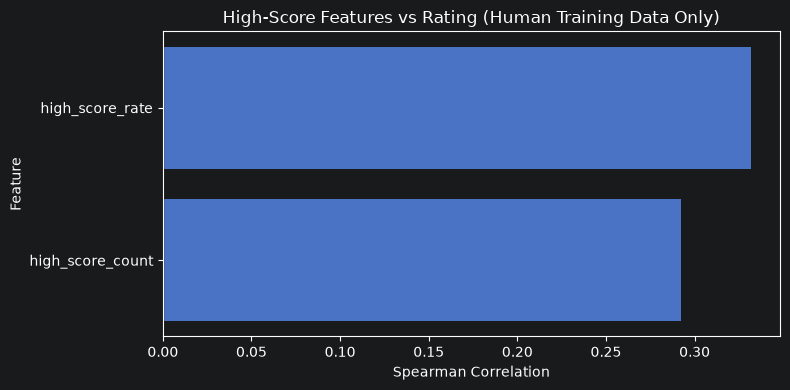

In [34]:

high_score_turns = turns.copy()

high_score_turns["is_high_score"] = (
    (high_score_turns["turn_type"] == "Play") &
    (high_score_turns["points"] >= 50)
).astype(int)

high_score_features = (
    high_score_turns.groupby(["game_id", "nickname"])
    .agg(
        high_score_count=("is_high_score", "sum"),
        high_score_rate=("is_high_score", "mean")
    )
    .reset_index()
)


high_score_cols = ["high_score_count", "high_score_rate"]

expanded_data = (
    expanded_data.drop(columns=high_score_cols, errors="ignore")
    .merge(
        high_score_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

bots = ["BetterBot", "HastyBot", "STEEBot"]

high_score_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()

assert set(high_score_train["game_id"]).isdisjoint(val_game_ids)

high_score_correlations = (
    high_score_train[high_score_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

display(high_score_correlations)

plt.figure(figsize=(8, 4))

sns.barplot(
    x=high_score_correlations.values,
    y=high_score_correlations.index
)

plt.title("High-Score Features vs Rating (Human Training Data Only)")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

Spearman correlation with rating
Human training data only


,Spearman
move_len_mean,0.295745
points_per_letter_mean,0.294118
difficult_word_mean,0.273834
difficult_word_sum,0.238090
move_len_max,0.226142
difficult_letters_mean,0.106811
difficult_letters_sum,0.024107
curr_board_pieces_used_mean,-0.264811



Missing values:


move_len_mean                  20
move_len_max                   20
difficult_word_mean            20
difficult_word_sum             20
difficult_letters_mean         20
difficult_letters_sum          20
points_per_letter_mean         20
curr_board_pieces_used_mean    20
dtype: int64

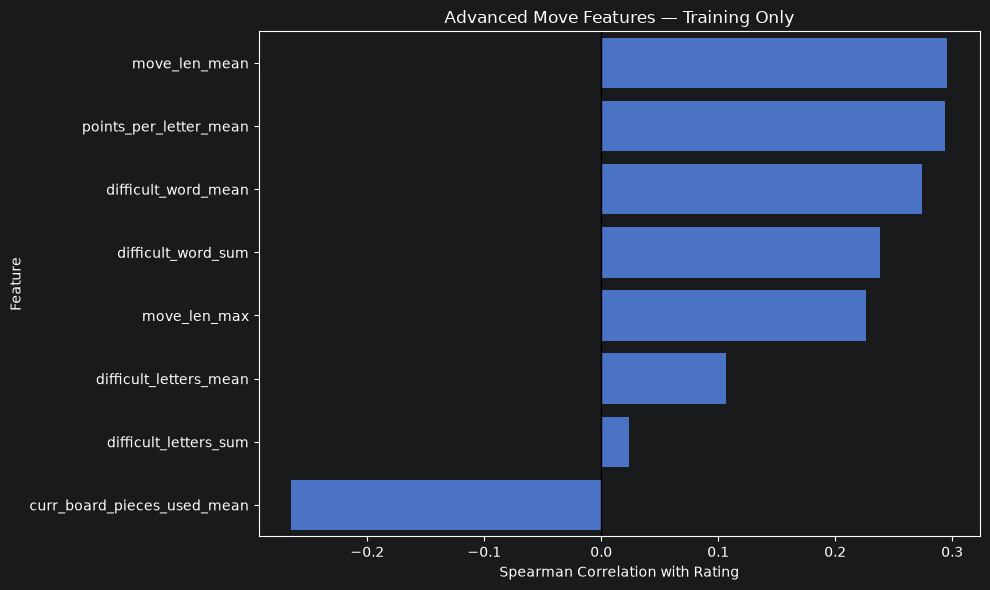


Example move notations:


,move_raw,move_letters,move_len,curr_board_pieces_used
0,DIG,DIG,3.0,0.0
1,HAP,HAP,3.0,0.0
2,LUTE,LUTE,4.0,0.0
3,UM,UM,2.0,0.0
4,..DICATE,DICATE,6.0,2.0
5,OXO,OXO,3.0,0.0
6,RAJAS,RAJAS,5.0,0.0
7,FAERIES,FAERIES,7.0,0.0
8,NEURON.L,NEURONL,7.0,1.0
9,HO,HO,2.0,0.0



Play moves containing '.': 918079


In [37]:

# ============================================================
# Advanced Scrabble Move Features
# Spearman correlations — HUMAN TRAINING DATA ONLY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Prepare Play turns
# ------------------------------------------------------------

t = turns.loc[
    turns["turn_type"] == "Play"
].copy()

# Keep move notation for inspecting board representation
t["move_raw"] = t["move"].astype("string")

# Extract uppercase letters
t["move_letters"] = (
    t["move_raw"]
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_len"] = t["move_letters"].str.len().astype(float)

# Unknown / empty moves should not become zero-length words
t.loc[t["move_len"] == 0, "move_len"] = np.nan

# ------------------------------------------------------------
# 2. Difficult words (PROXY: 7+ extracted letters)
# ------------------------------------------------------------

t["is_difficult_word"] = (
    t["move_len"] >= 7
).astype(float)

t.loc[
    t["move_len"].isna(), "is_difficult_word"
] = np.nan

# ------------------------------------------------------------
# 3. Difficult letters: J, Q, X, Z
# ------------------------------------------------------------

t["difficult_letters"] = (
    t["move_letters"]
    .str.count(r"[JQXZ]")
    .astype(float)
)

t.loc[
    t["move_len"].isna(), "difficult_letters"
] = np.nan

# ------------------------------------------------------------
# 4. Points per letter
# ------------------------------------------------------------

t["points_per_letter"] = (
    pd.to_numeric(t["points"], errors="coerce")
    / t["move_len"]
)

# ------------------------------------------------------------
# 5. Existing board tiles used (notation proxy)
# ------------------------------------------------------------

# Assumption: '.' represents a reused board tile.
# Verify this against actual move examples.
t["curr_board_pieces_used"] = (
    t["move_raw"]
    .str.count(r"\.")
    .astype(float)
)

t.loc[
    t["move_raw"].isna(), "curr_board_pieces_used"
] = np.nan

# ------------------------------------------------------------
# 6. Aggregate per player-game
# ------------------------------------------------------------

advanced_move_features = (
    t.groupby(["game_id", "nickname"])
    .agg(
        move_len_mean=("move_len", "mean"),
        move_len_max=("move_len", "max"),

        difficult_word_mean=("is_difficult_word", "mean"),
        difficult_word_sum=("is_difficult_word", "sum"),

        difficult_letters_mean=("difficult_letters", "mean"),
        difficult_letters_sum=("difficult_letters", "sum"),

        points_per_letter_mean=("points_per_letter", "mean"),

        curr_board_pieces_used_mean=(
            "curr_board_pieces_used", "mean"
        )
    )
    .reset_index()
)

advanced_cols = [
    "move_len_mean",
    "move_len_max",
    "difficult_word_mean",
    "difficult_word_sum",
    "difficult_letters_mean",
    "difficult_letters_sum",
    "points_per_letter_mean",
    "curr_board_pieces_used_mean"
]

# ------------------------------------------------------------
# 7. Merge safely into expanded_data
# ------------------------------------------------------------

original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=advanced_cols, errors="ignore")
    .merge(
        advanced_move_features,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

# ------------------------------------------------------------
# 8. Human training observations only
# ------------------------------------------------------------

bots = ["BetterBot", "HastyBot", "STEEBot"]

advanced_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & ~expanded_data["nickname"].isin(bots)
].copy()

# Verify no validation observations
assert set(advanced_train["game_id"]).isdisjoint(
    val_game_ids
)

# ------------------------------------------------------------
# 9. Spearman correlations with rating
# ------------------------------------------------------------

correlations = (
    advanced_train[advanced_cols + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Spearman correlation with rating")
print("Human training data only")
print("=" * 55)

display(correlations.to_frame("Spearman"))

# ------------------------------------------------------------
# 10. Missing values
# ------------------------------------------------------------

print("\nMissing values:")
display(
    advanced_train[advanced_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

# ------------------------------------------------------------
# 11. Visualize
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.values,
    y=correlations.index
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Spearman Correlation with Rating")
plt.ylabel("Feature")
plt.title("Advanced Move Features — Training Only")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. Inspect raw move notation
# ------------------------------------------------------------

print("\nExample move notations:")
display(
    t[
        ["move_raw", "move_letters", "move_len",
         "curr_board_pieces_used"]
    ].dropna().head(20)
)

print(
    "\nPlay moves containing '.':",
    int(t["move_raw"].str.contains(
        r"\.", regex=True, na=False
    ).sum())
)


In [35]:

base_features = selected_features.copy()

new_features = move_cols + move_rate_cols


features = base_features + new_features

print("Total features:", len(features))
print("Features:", features)

assert len(features) == len(set(features)), "Duplicate features found"
assert set(features).issubset(expanded_data.columns)
assert "rating" not in features

features = base_features + new_features

bots = ["BetterBot", "HastyBot", "STEEBot"]

human_data = expanded_data[
    ~expanded_data["nickname"].isin(bots)
].copy()

X = human_data[features]
y = human_data["rating"]


train_mask = human_data["game_id"].isin(train_game_ids)
val_mask = human_data["game_id"].isin(val_game_ids)

assert (train_mask | val_mask).all(), (
    "Found games absent from the original split"
)

assert not (train_mask & val_mask).any()

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]

# Verify no game overlap
train_games = set(human_data.loc[train_mask, "game_id"])
val_games = set(human_data.loc[val_mask, "game_id"])

assert train_games.isdisjoint(val_games)

categorical_cols = [
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason"
]

numerical_cols = [
    col for col in features
    if col not in categorical_cols
]


preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)

train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

train_mse = mean_squared_error(y_train, train_pred)
val_mse = mean_squared_error(y_val, val_pred)

print("Human-only Linear Regression — 21 features")
print("-" * 50)
print(f"Training observations:   {len(X_train):,}")
print(f"Validation observations: {len(X_val):,}")
print(f"Number of features:       {len(features)}")
print(f"Training MSE:             {train_mse:,.2f}")
print(f"Validation MSE:           {val_mse:,.2f}")
print(f"Validation RMSE:          {np.sqrt(val_mse):,.2f}")

Total features: 32
Features: ['score', 'avg_points', 'num_turns', 'max_points', 'std_points', 'game_duration_seconds', 'initial_time_seconds', 'increment_seconds', 'max_overtime_minutes', 'score_difference', 'rating_mode', 'lexicon', 'time_control_name', 'game_end_reason', 'played_first', 'player_won', 'count_Challenge', 'count_End', 'count_Exchange', 'count_Pass', 'count_Play', 'count_Six-Zero Rule', 'count_Timeout', 'count_Unknown', 'rate_Challenge', 'rate_End', 'rate_Exchange', 'rate_Pass', 'rate_Play', 'rate_Six-Zero Rule', 'rate_Timeout', 'rate_Unknown']
Human-only Linear Regression — 21 features
--------------------------------------------------
Training observations:   42,213
Validation observations: 8,197
Number of features:       32
Training MSE:             19,607.91
Validation MSE:           23,368.26
Validation RMSE:          152.87


In [40]:

# ============================================================
# Bot Gameplay Features + Human-Bot Differences
# No bot rating / No player history / No test data
# ============================================================

import numpy as np
import pandas as pd

bots = ["BetterBot", "HastyBot", "STEEBot"]

bot_feature_cols = [
    "bot_score",
    "bot_name",
    "bot_points_mean",
    "bot_move_len_mean",
    "avg_points_diff",
    "avg_move_len_diff",
    "avg_points_per_letter_diff"
]

# ------------------------------------------------------------
# 1. Calculate turn-level statistics
# ------------------------------------------------------------

t = turns.copy()

t["points_numeric"] = pd.to_numeric(
    t["points"], errors="coerce"
)

t["move_letters"] = (
    t["move"]
    .astype("string")
    .str.replace(r"[^A-Z]", "", regex=True)
)

t["move_length"] = (
    t["move_letters"].str.len().astype(float)
)

# Move statistics only for actual Play turns
is_play = t["turn_type"].eq("Play")

t.loc[~is_play | (t["move_length"] == 0),
      "move_length"] = np.nan

t["points_per_letter"] = (
    t["points_numeric"] /
    t["move_length"]
)

# ------------------------------------------------------------
# 2. Aggregate statistics for every player-game
# ------------------------------------------------------------

turn_stats = (
    t.groupby(["game_id", "nickname"])
    .agg(
        points_mean=("points_numeric", "mean"),
        move_len_mean=("move_length", "mean"),
        points_per_letter_mean=(
            "points_per_letter", "mean"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Identify bot observations
# ------------------------------------------------------------

# Use TRAIN only, never competition test.
bot_scores = train.loc[
    train["nickname"].isin(bots),
    ["game_id", "nickname", "score"]
].copy()

assert not bot_scores["game_id"].duplicated().any(), (
    "More than one bot per game detected"
)

bot_stats = bot_scores.merge(
    turn_stats,
    on=["game_id", "nickname"],
    how="left",
    validate="one_to_one"
)

bot_stats = bot_stats.rename(columns={
    "nickname": "bot_name",
    "score": "bot_score",
    "points_mean": "bot_points_mean",
    "move_len_mean": "bot_move_len_mean",
    "points_per_letter_mean": "bot_points_per_letter_mean"
})

# ------------------------------------------------------------
# 4. Add human and bot statistics
# ------------------------------------------------------------

human_stats = turn_stats.rename(columns={
    "points_mean": "human_points_mean",
    "move_len_mean": "human_move_len_mean",
    "points_per_letter_mean": "human_points_per_letter_mean"
})

human_rows = expanded_data.loc[
    ~expanded_data["nickname"].isin(bots),
    ["game_id", "nickname"]
].copy()

assert not human_rows.duplicated(
    ["game_id", "nickname"]
).any()

human_bot = (
    human_rows
    .merge(
        human_stats,
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        bot_stats[
            [
                "game_id",
                "bot_name",
                "bot_score",
                "bot_points_mean",
                "bot_move_len_mean",
                "bot_points_per_letter_mean"
            ]
        ],
        on="game_id",
        how="left",
        validate="many_to_one"
    )
)

# ------------------------------------------------------------
# 5. Calculate human-bot differences
# ------------------------------------------------------------

human_bot["avg_points_diff"] = (
    human_bot["human_points_mean"]
    - human_bot["bot_points_mean"]
)

human_bot["avg_move_len_diff"] = (
    human_bot["human_move_len_mean"]
    - human_bot["bot_move_len_mean"]
)

human_bot["avg_points_per_letter_diff"] = (
    human_bot["human_points_per_letter_mean"]
    - human_bot["bot_points_per_letter_mean"]
)

# ------------------------------------------------------------
# 6. Merge into expanded_data
# ------------------------------------------------------------

original_rows = len(expanded_data)

expanded_data = (
    expanded_data
    .drop(columns=bot_feature_cols, errors="ignore")
    .merge(
        human_bot[
            ["game_id", "nickname"] + bot_feature_cols
        ],
        on=["game_id", "nickname"],
        how="left",
        validate="one_to_one"
    )
)

assert len(expanded_data) == original_rows

# Every human game should have a bot opponent
human_mask = ~expanded_data["nickname"].isin(bots)

assert expanded_data.loc[
    human_mask, "bot_name"
].notna().all(), "Some human games have no bot opponent"

# ------------------------------------------------------------
# 7. Training-only correlations
# ------------------------------------------------------------

bot_train = expanded_data.loc[
    expanded_data["game_id"].isin(train_game_ids)
    & human_mask
].copy()

assert set(bot_train["game_id"]).isdisjoint(
    val_game_ids
)

numeric_bot_features = [
    col for col in bot_feature_cols
    if col != "bot_name"
]

correlations = (
    bot_train[numeric_bot_features + ["rating"]]
    .corr(method="spearman")["rating"]
    .drop("rating")
    .sort_values(ascending=False)
)

print("Bot feature correlations — HUMAN TRAINING ONLY")
print("=" * 55)

display(correlations.to_frame("Spearman"))

print("\nMissing values:")
display(
    bot_train[bot_feature_cols].isna().sum()
)

print("\nBot distribution in training:")
display(bot_train["bot_name"].value_counts())

print("\nExample:")
display(
    bot_train[
        ["nickname", "rating"] + bot_feature_cols
    ].head(10)
)


Bot feature correlations — HUMAN TRAINING ONLY


,Spearman
bot_points_mean,0.269491
bot_move_len_mean,0.228746
bot_score,0.129148
avg_points_diff,0.089367
avg_move_len_diff,0.075046
avg_points_per_letter_diff,0.074076



Missing values:


bot_score                      0
bot_name                       0
bot_points_mean                0
bot_move_len_mean              0
avg_points_diff                0
avg_move_len_diff             20
avg_points_per_letter_diff    20
dtype: int64


Bot distribution in training:


bot_name
HastyBot     14793
BetterBot    13924
STEEBot      13496
Name: count, dtype: int64


Example:


,nickname,rating,bot_score,bot_name,bot_points_mean,bot_move_len_mean,avg_points_diff,avg_move_len_diff,avg_points_per_letter_diff
1,stevy,1500,335.0,BetterBot,25.769231,4.000000,4.873626,-0.538462,3.067033
2,davidavid,1811,318.0,BetterBot,24.461538,3.750000,6.967033,-0.057692,2.141346
4,Inandoutworker,1473,478.0,BetterBot,31.866667,3.666667,-23.366667,-2.083333,-3.750873
6,stevy,1500,427.0,STEEBot,28.466667,3.733333,-8.154167,-0.876190,1.434127
12,cccc,1641,464.0,BetterBot,33.142857,3.500000,-8.876190,0.038462,-1.443407
15,squashy,1838,415.0,BetterBot,27.666667,3.571429,-6.309524,0.095238,-1.361139
16,BB-8,1500,408.0,HastyBot,24.000000,3.400000,-0.600000,-0.114286,-1.330952
18,Trayz,2017,381.0,STEEBot,29.307692,4.416667,10.146853,-0.780303,4.317677
21,meetsumeet,1863,451.0,STEEBot,34.692308,4.083333,-1.108974,-0.500000,3.483135
23,Mimix,1829,385.0,BetterBot,22.647059,3.312500,5.219608,-0.081731,4.172436


In [51]:
advanced_selected_features = [
    "move_len_mean",
    "points_per_letter_mean",
    "difficult_word_mean",
    "curr_board_pieces_used_mean"
]

# Avoid including two versions of average move length
move_features_updated = [
    col for col in selected_move_features
    if col != "move_length_mean"
]

features = list(dict.fromkeys(
    base_features
    + new_features
    + ["high_score_count", "high_score_rate"]
    + move_features_updated
    + advanced_selected_features
    + bot_feature_cols
))

print(f"Total features: {len(features)}")


bots = ["BetterBot", "HastyBot", "STEEBot"]

human_data = expanded_data[
    ~expanded_data["nickname"].isin(bots)
].copy()

X = human_data[features]
y = human_data["rating"]


train_mask = human_data["game_id"].isin(train_game_ids)
val_mask = human_data["game_id"].isin(val_game_ids)

assert (train_mask | val_mask).all(), (
    "Found games absent from the original split"
)

assert not (train_mask & val_mask).any()

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]

train_games = set(human_data.loc[train_mask, "game_id"])
val_games = set(human_data.loc[val_mask, "game_id"])

assert train_games.isdisjoint(val_games)


categorical_cols = [
    "rating_mode",
    "lexicon",
    "time_control_name",
    "game_end_reason",
    "bot_name"

]

numerical_cols = [
    col for col in features
    if col not in categorical_cols
]


preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_cols)
])

# XGBoost
model = Pipeline([
    ("preprocessing", preprocessor),
    ("boost", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    ))
])

# vit on training data only
model.fit(X_train, y_train)

# predictions
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

# evaluation
train_mse = mean_squared_error(y_train, train_pred)
val_mse = mean_squared_error(y_val, val_pred)

print(f"Human-only XGBoost — {len(features)} features")
print("-" * 50)
print(f"Training observations:   {len(X_train):,}")
print(f"Validation observations: {len(X_val):,}")
print(f"Number of features:       {len(features)}")
print(f"Training MSE:             {train_mse:,.2f}")
print(f"Training RMSE:            {np.sqrt(train_mse):,.2f}")
print(f"Validation MSE:           {val_mse:,.2f}")
print(f"Validation RMSE:          {np.sqrt(val_mse):,.2f}")

Total features: 47
Human-only XGBoost — 47 features
--------------------------------------------------
Training observations:   42,213
Validation observations: 8,197
Number of features:       47
Training MSE:             11,823.46
Training RMSE:            108.74
Validation MSE:           20,795.22
Validation RMSE:          144.21
